# Data-Driven Imputation of Missing Economic Indicators for EU Regions: A Multi-Metric Accuracy Assessment

## Notebook 2 – Hyperparameter-optimized models

**Authors:** Irmantas Pilypas, Irma Šileikienė, Asta Slotkienė
**Institution:** Vilnius Gediminas Technical University

---

## Study description

This study examines the effectiveness of the XGBoost and Random Forest algorithms for imputing missing economic indicator values at the EU NUTS 2 regional level. Separate Random Forest and XGBoost models are developed for each economic indicator, and imputation accuracy is evaluated using the nRMSE, nMAE, R² and sMAPE metrics with five-fold cross-validation.

This notebook implements the **hyperparameter-optimized** experiment: Random Forest and XGBoost models whose hyperparameters are tuned with RandomizedSearchCV before being evaluated with the same five-fold cross-validation framework and accuracy metrics as the baseline models (Notebook 1).

**Article outputs reproduced in this notebook:**
- Table 3 – Hyperparameter-optimized Random Forest and XGBoost model performance metrics (nRMSE, nMAE, R²) using 5-fold cross-validation
- Table 5 – Overall cross-validation performance of optimized imputation models
- Figure 6 – nRMSE and nMAE error distribution for hyperparameter-optimized Random Forest and XGBoost models (youth unemployment rate, ROD5)
- Figure 4 – Comparison of R² values for baseline and optimized Random Forest and XGBoost models across economic indicators (requires `results/cv_metrics_baseline.csv` produced by Notebook 1)

**Data:**
- **260** NUTS 2 regions
- **8** economic indicators (ROD1–ROD8)
- **Period:** 1990–2023
- **Total:** 6,984 observations
- **Source:** Eurostat

**Evaluation metrics** (Equations (3)–(6) of the article):

$$nRMSE = \frac{\sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i-\hat{y}_i\right)^2}}{y_{max}-y_{min}} \qquad
nMAE = \frac{\frac{1}{n}\sum_{i=1}^{n}\left|y_i-\hat{y}_i\right|}{y_{max}-y_{min}}$$

$$R^2 = 1-\frac{\sum_{i=1}^{n}\left(y_i-\hat{y}_i\right)^2}{\sum_{i=1}^{n}\left(y_i-\bar{y}\right)^2} \qquad
sMAPE = \frac{100\%}{n}\sum_{i=1}^{n}\frac{\left|y_i-\hat{y}_i\right|}{\left(\left|y_i\right|+\left|\hat{y}_i\right|\right)/2}$$

where $y_i$ is the actual value of the $i$-th observation, $\hat{y}_i$ is the predicted value, $\bar{y}$ is the mean of the actual values and $n$ is the number of observations. nRMSE and nMAE are normalized by the range of the actual values in each validation fold.

## 1. Environment setup

The study is conducted in Python with the scikit-learn and xgboost libraries. The Random Forest and XGBoost imputation models are implemented in the `imputation_models/` package.

> **Reproducibility note.** The results reported in the article were obtained with **xgboost ≥ 3.0** (scikit-learn 1.5.2). Earlier xgboost versions (e.g. 2.x) use different internal defaults and produce slightly different XGBoost metrics. The exact package versions are listed in `requirements.txt`.

In [1]:
# ============================================================================
# LIBRARY IMPORTS
# ============================================================================

import os
import time
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import sklearn
import xgboost
from matplotlib.patches import Patch
from IPython.display import display

from imputation_models import RandomForestImputer, XGBoostImputer

# Configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_theme(font_scale=1.2)
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.unicode_minus'] = False

# Output directories
RESULTS_DIR = 'results'
FIGURES_DIR = os.path.join(RESULTS_DIR, 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

print(f"Python:       {platform.python_version()}")
print(f"numpy:        {np.__version__}")
print(f"pandas:       {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"xgboost:      {xgboost.__version__}")

if int(xgboost.__version__.split('.')[0]) < 3:
    print("\nWARNING: xgboost < 3.0 detected. The XGBoost metrics may differ slightly "
          "from the values reported in the article (obtained with xgboost >= 3.0).")

Python:       3.11.9
numpy:        2.0.2
pandas:       2.2.3
scikit-learn: 1.5.2
xgboost:      3.1.3


## 2. Data loading and preparation

The NUTS 2 regional economic indicators dataset was compiled from the official database of the European Union Statistical Office (Eurostat). For more explicit indicator identification in the subsequent analysis, the indicators are denoted by the indices **ROD1–ROD8** (Table 1).

In [2]:
# ============================================================================
# DATA LOADING
# ============================================================================

DATA_PATH = os.path.join('uploads', 'nuts2_economic_indicators_2026-10-29.csv')

df_raw = pd.read_csv(DATA_PATH)

print(f"Data loaded: {len(df_raw):,} rows, {len(df_raw.columns)} columns")
print(f"Columns: {', '.join(df_raw.columns)}")
display(df_raw.head())

Data loaded: 6,984 rows, 10 columns
Columns: geo, year, employment_rate, rd_expenditure_pct_gdp, unemployment_rate, tertiary_education_pct, youth_unemployment_rate, population_density, long_term_unemployment_share, female_employment_rate


,geo,year,employment_rate,rd_expenditure_pct_gdp,unemployment_rate,tertiary_education_pct,youth_unemployment_rate,population_density,long_term_unemployment_share,female_employment_rate
0,AL01,2012,NaN,NaN,NaN,NaN,NaN,79.2,NaN,NaN
1,AL01,2013,NaN,NaN,NaN,NaN,NaN,78.5,NaN,NaN
2,AL01,2014,NaN,NaN,NaN,NaN,NaN,77.7,NaN,NaN
3,AL01,2015,NaN,NaN,NaN,NaN,NaN,77.0,NaN,NaN
4,AL01,2016,NaN,NaN,NaN,NaN,NaN,76.6,NaN,NaN


In [3]:
# ============================================================================
# INDICATOR IDENTIFIERS (ROD1-ROD8, Table 1)
# ============================================================================

INDICATORS = {
    'ROD1': 'employment_rate',
    'ROD2': 'rd_expenditure_pct_gdp',
    'ROD3': 'unemployment_rate',
    'ROD4': 'tertiary_education_pct',
    'ROD5': 'youth_unemployment_rate',
    'ROD6': 'population_density',
    'ROD7': 'long_term_unemployment_share',
    'ROD8': 'female_employment_rate',
}
INDICATOR_IDS = list(INDICATORS)

df = df_raw.rename(columns={name: ind_id for ind_id, name in INDICATORS.items()})

print("Indicator identifiers:")
for ind_id, name in INDICATORS.items():
    print(f"  {ind_id} = {name}")

print("\nDataset summary:")
print(f"  NUTS 2 regions:      {df['geo'].nunique()}")
print(f"  Period:              {df['year'].min()}-{df['year'].max()}")
print(f"  Observations:        {len(df):,}")
print(f"  Economic indicators: {len(INDICATOR_IDS)}")

Indicator identifiers:
  ROD1 = employment_rate
  ROD2 = rd_expenditure_pct_gdp
  ROD3 = unemployment_rate
  ROD4 = tertiary_education_pct
  ROD5 = youth_unemployment_rate
  ROD6 = population_density
  ROD7 = long_term_unemployment_share
  ROD8 = female_employment_rate

Dataset summary:
  NUTS 2 regions:      260
  Period:              1990-2023
  Observations:        6,984
  Economic indicators: 8


The exploratory data analysis of this dataset (Table 1, Figures 1–2) is presented in Notebook 1 (baseline models).

## 3. Methodology

The research methodology consists of the following steps, applied separately to **each economic indicator with missing values** (a separate Random Forest and a separate XGBoost model per indicator):

1. **Test data creation** – 20% of the non-missing values of the indicator are randomly removed (`random_state = 42`; zero values are never used as test values). The removed values are later used to evaluate imputation accuracy (test set predictions, Figures 5–6).
2. **Predictors** – the other economic indicators are used as predictors (independent variables), together with the region (`geo`) and year (`year`) identifiers, which are ordinal-encoded. Missing predictor values are filled with the column mean (ignoring zeros). The original (non-imputed) values are always used as predictors, so imputation errors of one indicator do not propagate to the others.
3. **Five-fold cross-validation** – the models are evaluated with five-fold cross-validation (`KFold`, shuffled, `random_state = 42`) on the remaining 80% of the known values. In each fold, nRMSE, nMAE, R² and sMAPE are computed; the article reports the **mean ± standard deviation across the five folds** (Tables 2 and 3). The overall results (Tables 4 and 5) are the means of the per-indicator CV values across the eight indicators, ± their standard deviation.
4. **Imputation** – the final model is trained on 100% of the known values of the indicator and used to predict (impute) its missing values.
5. **Feature importance analysis** – the importance of each predictor is analysed for each economic indicator.

**Hyperparameter optimization.** Before the evaluation, the hyperparameters of each model (for each indicator separately) are tuned with **RandomizedSearchCV** (30 sampled configurations, 3-fold CV, scoring = R², `random_state = 42`) on the known values of the indicator. The best configuration is then evaluated with the same test data, five-fold cross-validation framework and accuracy metrics as the baseline models, allowing a direct and consistent comparison.

**Hyperparameter search space:**

| Random Forest | Search space | XGBoost | Search space |
|---|---|---|---|
| `n_estimators` | integers 50–300 | `n_estimators` | integers 50–300 |
| `max_depth` | 5, 10, 15, 20, 25, 30, None | `max_depth` | integers 3–15 |
| `min_samples_split` | integers 2–20 | `learning_rate` | uniform 0.01–0.30 |
| `min_samples_leaf` | integers 1–10 | `subsample` | uniform 0.6–1.0 |
| `max_features` | `'sqrt'`, `'log2'`, 0.3, 0.5, 0.7 | `colsample_bytree` | uniform 0.6–1.0 |
| | | `min_child_weight` | integers 1–10 |
| | | `reg_alpha` | uniform 0–1 |
| | | `reg_lambda` | uniform 0–1 |

In [4]:
# ============================================================================
# FEATURE IMPORTANCE PLOT (all indicators in one figure)
# ============================================================================

def plot_feature_importance(feature_importance, model_name, cmap):
    """Horizontal bar charts of feature importance for each imputed indicator."""
    indicators = list(feature_importance.keys())
    n_cols = 2
    n_rows = (len(indicators) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4.5 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    for ax, indicator in zip(axes, indicators):
        imp_df = (pd.DataFrame(list(feature_importance[indicator].items()), columns=['Feature', 'Importance'])
                  .sort_values('Importance', ascending=False))
        colors = cmap(np.linspace(0.2, 0.95, len(imp_df)))
        bars = ax.barh(range(len(imp_df)), imp_df['Importance'], color=colors,
                       edgecolor='black', linewidth=0.8, alpha=0.85)
        ax.set_yticks(range(len(imp_df)))
        ax.set_yticklabels(imp_df['Feature'], fontsize=10)
        ax.set_xlabel('Importance', fontsize=11, fontweight='bold')
        ax.set_title(indicator, fontsize=13, fontweight='bold', pad=8)
        ax.grid(axis='x', alpha=0.3, linestyle='--', linewidth=0.7)
        ax.invert_yaxis()
        for bar, val in zip(bars, imp_df['Importance']):
            ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2, f'{val:.3f}',
                    va='center', ha='left', fontsize=9, fontweight='bold')
        ax.set_xlim(0, imp_df['Importance'].max() * 1.15)

    for ax in axes[len(indicators):]:
        ax.axis('off')

    plt.suptitle(f'{model_name} - feature importance', fontsize=16, fontweight='bold', y=1.0)
    plt.tight_layout()
    plt.show()

    # Most important predictor for each indicator
    top = {ind: next(iter(fi.items())) for ind, fi in feature_importance.items()}
    print("Most important predictor for each indicator:")
    for ind, (feature, value) in top.items():
        print(f"  {ind}: {feature} ({value:.3f})")

## 4. Hyperparameter-optimized Random Forest model

### 4.1 Hyperparameter optimization, model training, five-fold cross-validation and imputation

In [5]:
# ============================================================================
# RANDOM FOREST MODEL (HYPERPARAMETER-OPTIMIZED) - TRAINING, CROSS-VALIDATION AND IMPUTATION
# ============================================================================

CV_FOLDS = 5          # five-fold cross-validation
USE_HYPEROPT = True   # hyperparameter optimization with RandomizedSearchCV
HYPEROPT_N_ITER = 30  # number of sampled hyperparameter configurations
HYPEROPT_CV = 3       # CV folds used in the hyperparameter search

rf_imputer = RandomForestImputer(
    cv_folds=CV_FOLDS,
    use_hyperopt=USE_HYPEROPT,
    hyperopt_n_iter=HYPEROPT_N_ITER,
    hyperopt_cv=HYPEROPT_CV,
)
rf_imputer.print_params()
print()

start_time = time.time()
df_imputed_rf = rf_imputer.fit_and_impute(df.copy())
elapsed_time = time.time() - start_time
print(f"Training time: {elapsed_time:.2f} s ({elapsed_time / 60:.2f} min)\n")

# Cross-validation results (mean ± standard deviation across the five folds)
rf_imputer.print_cv_results()

# Summary of the best hyperparameters found
rf_imputer.print_best_params()

rf_metrics_df = rf_imputer.get_cv_metrics_df()

Random Forest hyperparameters:
  - n_estimators: 100
  - max_depth: 15
  - min_samples_split: 5
  - min_samples_leaf: 2
  - max_features: sqrt
  - random_state: 42
  - cv_folds: 5
  - use_hyperopt: True
  - hyperopt_n_iter: 30
  - hyperopt_cv: 3

Hyperparameter optimization ENABLED (RandomizedSearchCV)
  - Number of iterations: 30
  - CV folds used in the search: 3



Training time: 227.49 s (3.79 min)

CROSS-VALIDATION RESULTS (5-fold CV)

OVERALL MEANS (across all indicators):
--------------------------------------------------
  R²:    0.8163 ± 0.1817
  nRMSE: 0.0577 ± 0.0229
  nMAE:  0.0385 ± 0.0142
  sMAPE: 25.70% ± 28.35%

CV RESULTS BY INDICATOR:
------------------------------------------------------------------------------------------

ROD1:
  R²:    0.9798 ± 0.0012
  nRMSE: 0.0275 ± 0.0009
  nMAE:  0.0209 ± 0.0005
  sMAPE: 1.45 ± 0.03%

ROD2:
  R²:    0.6850 ± 0.0651
  nRMSE: 0.0719 ± 0.0087
  nMAE:  0.0438 ± 0.0091
  sMAPE: 33.98 ± 1.83%

ROD3:
  R²:    0.9406 ± 0.0041
  nRMSE: 0.0445 ± 0.0026
  nMAE:  0.0321 ± 0.0017
  sMAPE: 11.95 ± 0.36%

ROD4:
  R²:    0.7881 ± 0.0055
  nRMSE: 0.0856 ± 0.0018
  nMAE:  0.0643 ± 0.0009
  sMAPE: 15.03 ± 0.47%

ROD5:
  R²:    0.8674 ± 0.0110
  nRMSE: 0.0666 ± 0.0054
  nMAE:  0.0496 ± 0.0042
  sMAPE: 18.45 ± 0.74%

ROD6:
  R²:    0.4043 ± 0.0494
  nRMSE: 0.0887 ± 0.0038
  nMAE:  0.0439 ± 0.0010
  sMAPE: 95.4

### 4.2 Selected hyperparameters

In [6]:
# ============================================================================
# SELECTED HYPERPARAMETERS FOR EACH INDICATOR (Random Forest)
# ============================================================================

rf_best_params_df = pd.DataFrame.from_dict(
    {ind: {p: ('None' if val is None else val) for p, val in params.items()}
     for ind, params in rf_imputer.get_best_params().items()},
    orient='index').astype(object)
rf_best_params_df.index.name = 'Indicator ID'
rf_best_params_df = rf_best_params_df[sorted(rf_best_params_df.columns)]
display(rf_best_params_df)

,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
Indicator ID,,,,,
ROD1,20,0.7,4,6,200
ROD2,None,0.3,3,3,219
ROD3,20,0.7,4,6,200
ROD4,None,0.3,9,16,64
ROD5,5,0.7,3,13,153
ROD6,5,0.3,3,2,172
ROD7,5,0.7,3,13,153
ROD8,25,0.7,1,8,58


### 4.3 Feature importance analysis

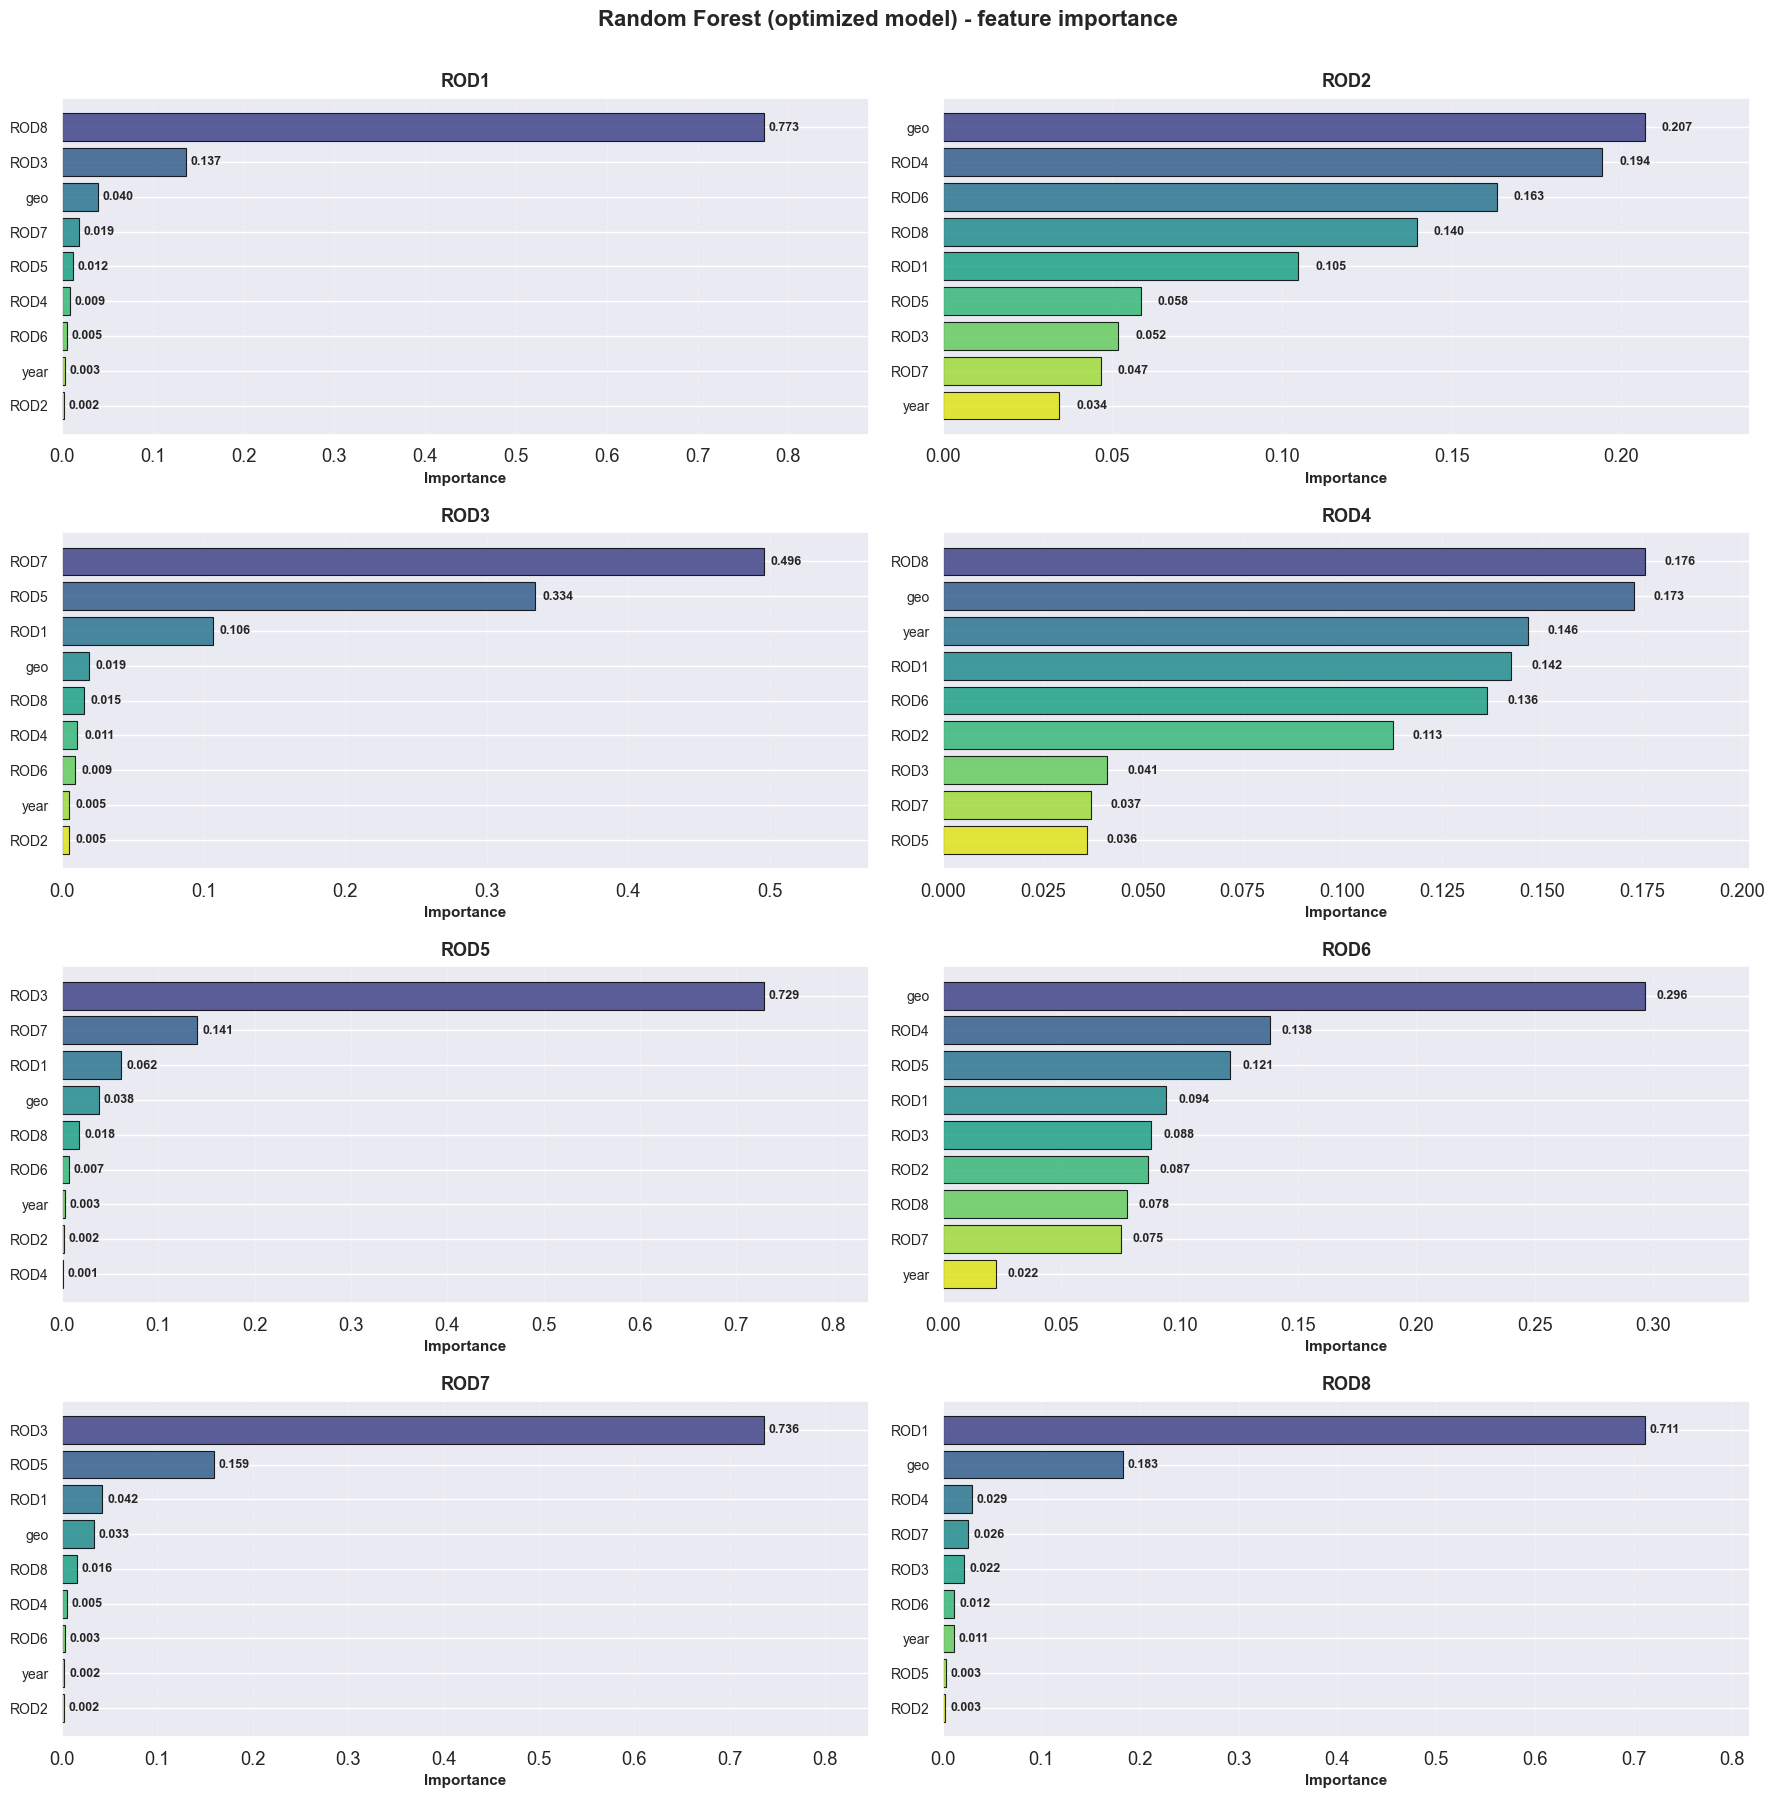

Most important predictor for each indicator:
  ROD1: ROD8 (0.773)
  ROD2: geo (0.207)
  ROD3: ROD7 (0.496)
  ROD4: ROD8 (0.176)
  ROD5: ROD3 (0.729)
  ROD6: geo (0.296)
  ROD7: ROD3 (0.736)
  ROD8: ROD1 (0.711)


In [7]:
plot_feature_importance(rf_imputer.get_feature_importance(), 'Random Forest (optimized model)', plt.cm.viridis)

## 5. Hyperparameter-optimized XGBoost model

### 5.1 Hyperparameter optimization, model training, five-fold cross-validation and imputation

In [8]:
# ============================================================================
# XGBOOST MODEL (HYPERPARAMETER-OPTIMIZED) - TRAINING, CROSS-VALIDATION AND IMPUTATION
# ============================================================================

CV_FOLDS = 5          # five-fold cross-validation
USE_HYPEROPT = True   # hyperparameter optimization with RandomizedSearchCV
HYPEROPT_N_ITER = 30  # number of sampled hyperparameter configurations
HYPEROPT_CV = 3       # CV folds used in the hyperparameter search

xgb_imputer = XGBoostImputer(
    cv_folds=CV_FOLDS,
    use_hyperopt=USE_HYPEROPT,
    hyperopt_n_iter=HYPEROPT_N_ITER,
    hyperopt_cv=HYPEROPT_CV,
)
xgb_imputer.print_params()
print()

start_time = time.time()
df_imputed_xgb = xgb_imputer.fit_and_impute(df.copy())
elapsed_time = time.time() - start_time
print(f"Training time: {elapsed_time:.2f} s ({elapsed_time / 60:.2f} min)\n")

# Cross-validation results (mean ± standard deviation across the five folds)
xgb_imputer.print_cv_results()

# Summary of the best hyperparameters found
xgb_imputer.print_best_params()

xgb_metrics_df = xgb_imputer.get_cv_metrics_df()

XGBoost hyperparameters:
  - n_estimators: 200
  - learning_rate: 0.1
  - max_depth: 6
  - subsample: 0.8
  - colsample_bytree: 0.8
  - min_child_weight: 3
  - reg_alpha: 0.1
  - reg_lambda: 0.1
  - random_state: 42
  - cv_folds: 5
  - use_hyperopt: True
  - hyperopt_n_iter: 30
  - hyperopt_cv: 3

Hyperparameter optimization ENABLED (RandomizedSearchCV)
  - Number of iterations: 30
  - CV folds used in the search: 3



Training time: 147.10 s (2.45 min)

CROSS-VALIDATION RESULTS (5-fold CV)

OVERALL MEANS (across all indicators):
--------------------------------------------------
  R²:    0.9304 ± 0.0549
  nRMSE: 0.0391 ± 0.0142
  nMAE:  0.0262 ± 0.0109
  sMAPE: 15.43% ± 12.14%

CV RESULTS BY INDICATOR:
------------------------------------------------------------------------------------------

ROD1:
  R²:    0.9845 ± 0.0012
  nRMSE: 0.0240 ± 0.0008
  nMAE:  0.0183 ± 0.0005
  sMAPE: 1.27 ± 0.03%

ROD2:
  R²:    0.8067 ± 0.0617
  nRMSE: 0.0555 ± 0.0072
  nMAE:  0.0321 ± 0.0064
  sMAPE: 27.73 ± 1.18%

ROD3:
  R²:    0.9566 ± 0.0040
  nRMSE: 0.0380 ± 0.0028
  nMAE:  0.0269 ± 0.0016
  sMAPE: 10.22 ± 0.35%

ROD4:
  R²:    0.8931 ± 0.0076
  nRMSE: 0.0607 ± 0.0017
  nMAE:  0.0457 ± 0.0011
  sMAPE: 10.69 ± 0.40%

ROD5:
  R²:    0.9213 ± 0.0060
  nRMSE: 0.0513 ± 0.0029
  nMAE:  0.0365 ± 0.0025
  sMAPE: 13.15 ± 0.39%

ROD6:
  R²:    0.9554 ± 0.0093
  nRMSE: 0.0241 ± 0.0015
  nMAE:  0.0099 ± 0.0005
  sMAPE: 39.6

### 5.2 Selected hyperparameters

In [9]:
# ============================================================================
# SELECTED HYPERPARAMETERS FOR EACH INDICATOR (XGBoost)
# ============================================================================

xgb_best_params_df = pd.DataFrame.from_dict(
    {ind: {p: ('None' if val is None else val) for p, val in params.items()}
     for ind, params in xgb_imputer.get_best_params().items()},
    orient='index').round(4)
xgb_best_params_df.index.name = 'Indicator ID'
xgb_best_params_df = xgb_best_params_df[sorted(xgb_best_params_df.columns)]
display(xgb_best_params_df)

,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample
Indicator ID,,,,,,,,
ROD1,0.9934,0.1257,3,9,173,0.5082,0.6958,0.9433
ROD2,0.8426,0.0127,11,3,202,0.0051,0.1608,0.8195
ROD3,0.9509,0.0848,14,10,161,0.5552,0.5297,0.6967
ROD4,0.6206,0.0908,3,1,196,0.6807,0.5309,0.7791
ROD5,0.7035,0.2021,4,6,103,0.5467,0.1849,0.9878
ROD6,0.6028,0.1581,11,5,274,0.1199,0.3376,0.9772
ROD7,0.7837,0.1068,10,8,180,0.0206,0.9699,0.9330
ROD8,0.9425,0.1273,3,8,165,0.0841,0.1616,0.9594


### 5.3 Feature importance analysis

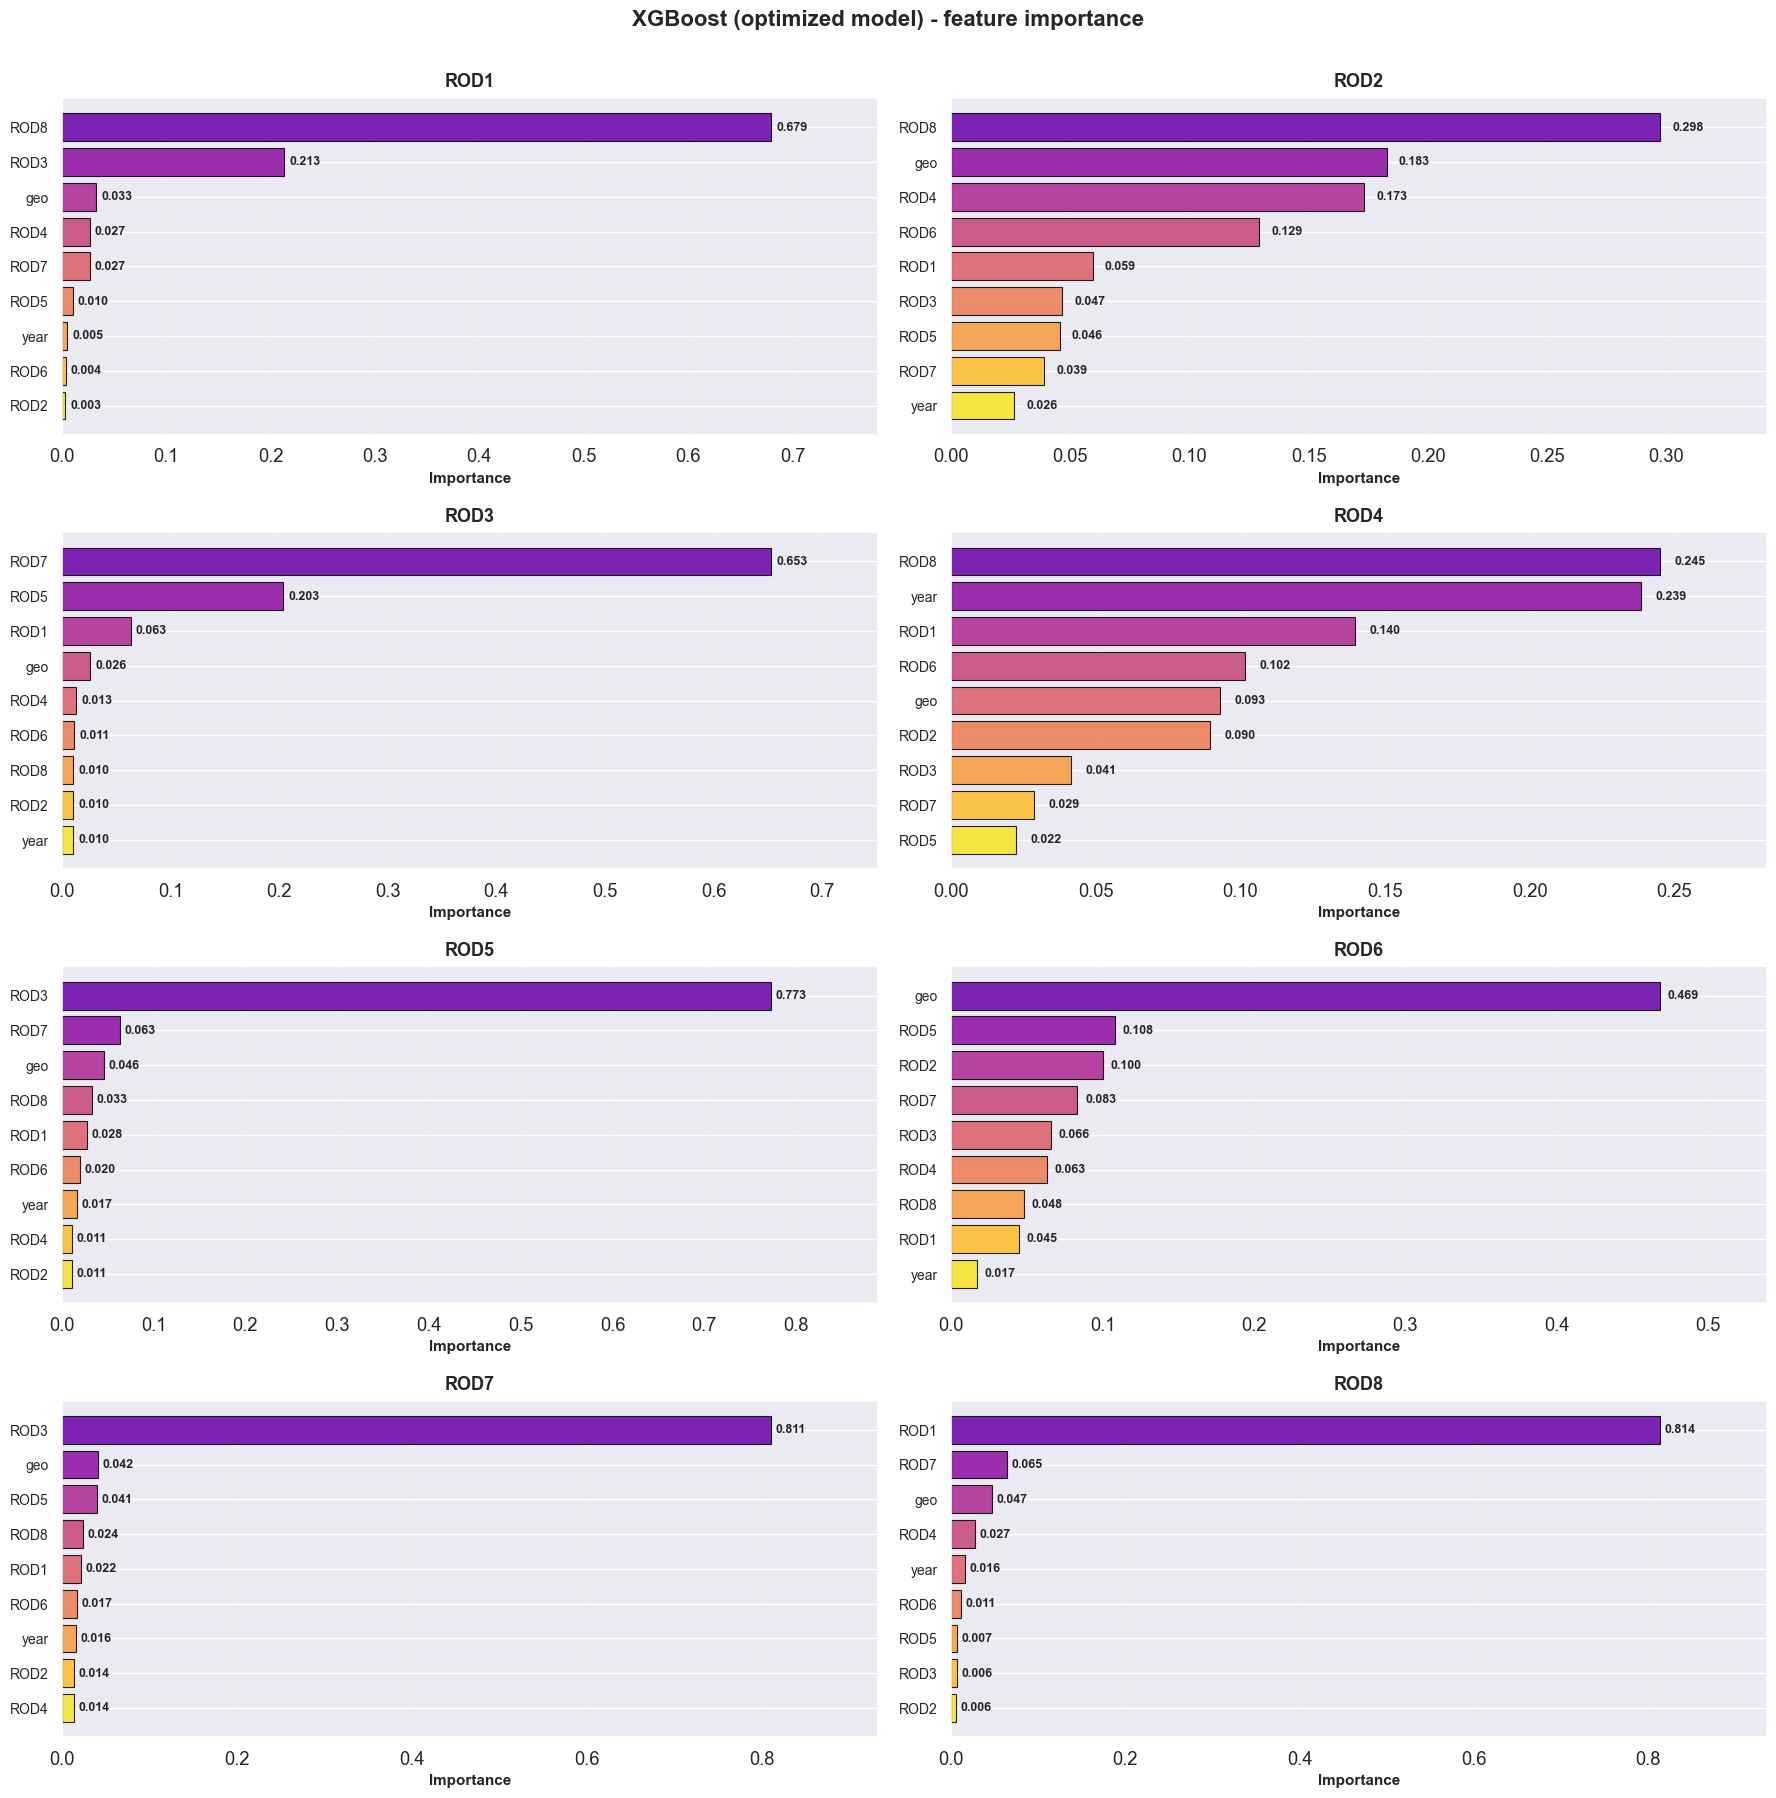

Most important predictor for each indicator:
  ROD1: ROD8 (0.679)
  ROD2: ROD8 (0.298)
  ROD3: ROD7 (0.653)
  ROD4: ROD8 (0.245)
  ROD5: ROD3 (0.773)
  ROD6: geo (0.469)
  ROD7: ROD3 (0.811)
  ROD8: ROD1 (0.814)


In [10]:
plot_feature_importance(xgb_imputer.get_feature_importance(), 'XGBoost (optimized model)', plt.cm.plasma)

## 6. Results: hyperparameter-optimized models

In [11]:
# ============================================================================
# HELPER FUNCTIONS FOR THE RESULT TABLES
# ============================================================================

def indicator_metrics_table(rf_df, xgb_df):
    """Per-indicator CV metrics (mean ± std across folds) for both models, as in Tables 2-3."""
    rf_df = rf_df.set_index('Indicator')
    xgb_df = xgb_df.set_index('Indicator')
    table = pd.DataFrame({
        ('Random Forest', 'nRMSE'): rf_df['nRMSE_formatted'],
        ('Random Forest', 'nMAE'): rf_df['nMAE_formatted'],
        ('Random Forest', 'R²'): rf_df['R²_formatted'],
        ('XGBoost', 'nRMSE'): xgb_df['nRMSE_formatted'],
        ('XGBoost', 'nMAE'): xgb_df['nMAE_formatted'],
        ('XGBoost', 'R²'): xgb_df['R²_formatted'],
    })
    table.index.name = 'Indicator ID'
    return table


def overall_metrics_table(rf_imp, xgb_imp):
    """Overall CV performance across all indicators (mean ± std), as in Tables 4-5."""
    rf_s, xgb_s = rf_imp.get_cv_summary(), xgb_imp.get_cv_summary()
    rows = [('R²', 'r2', 4), ('nRMSE', 'nrmse', 4), ('nMAE', 'nmae', 4), ('sMAPE', 'smape', 2)]
    return pd.DataFrame({
        'Metric': [label for label, _, _ in rows],
        'Random Forest (CV)': [f"{rf_s[k + '_mean']:.{d}f} ± {rf_s[k + '_std']:.{d}f}" for _, k, d in rows],
        'XGBoost (CV)': [f"{xgb_s[k + '_mean']:.{d}f} ± {xgb_s[k + '_std']:.{d}f}" for _, k, d in rows],
    })


def better_model_counts(rf_df, xgb_df):
    """Number of indicators for which each model achieves the better CV mean of each metric."""
    rf_df = rf_df.set_index('Indicator')
    xgb_df = xgb_df.set_index('Indicator')
    rows = []
    for metric, higher_is_better in [('R²', True), ('nRMSE', False), ('nMAE', False), ('sMAPE (%)', False)]:
        xgb_better = (xgb_df[metric] > rf_df[metric]) if higher_is_better else (xgb_df[metric] < rf_df[metric])
        rows.append({'Metric': metric.replace(' (%)', ''),
                     'XGBoost better': int(xgb_better.sum()),
                     'Random Forest better': int((~xgb_better).sum())})
    return pd.DataFrame(rows)

### 6.1 Performance by indicator (Table 3)

In [12]:
# ============================================================================
# TABLE 3. HYPERPARAMETER-OPTIMIZED RANDOM FOREST AND XGBOOST MODEL PERFORMANCE METRICS (NRMSE, NMAE, R²) USING 5-FOLD CROSS-VALIDATION
# ============================================================================

table_by_indicator = indicator_metrics_table(rf_metrics_df, xgb_metrics_df)

print("Table 3. Hyperparameter-optimized Random Forest and XGBoost model performance metrics (nRMSE, nMAE, R²) using 5-fold cross-validation")
display(table_by_indicator)

print("Number of indicators for which each model achieves the better CV mean:")
display(better_model_counts(rf_metrics_df, xgb_metrics_df).style.hide(axis='index'))

Table 3. Hyperparameter-optimized Random Forest and XGBoost model performance metrics (nRMSE, nMAE, R²) using 5-fold cross-validation


Random Forest                                    \
                        nRMSE             nMAE               R²   
Indicator ID                                                      
ROD1          0.0275 ± 0.0009  0.0209 ± 0.0005  0.9798 ± 0.0012   
ROD2          0.0719 ± 0.0087  0.0438 ± 0.0091  0.6850 ± 0.0651   
ROD3          0.0445 ± 0.0026  0.0321 ± 0.0017  0.9406 ± 0.0041   
ROD4          0.0856 ± 0.0018  0.0643 ± 0.0009  0.7881 ± 0.0055   
ROD5          0.0666 ± 0.0054  0.0496 ± 0.0042  0.8674 ± 0.0110   
ROD6          0.0887 ± 0.0038  0.0439 ± 0.0010  0.4043 ± 0.0494   
ROD7          0.0512 ± 0.0027  0.0350 ± 0.0024  0.8851 ± 0.0084   
ROD8          0.0256 ± 0.0016  0.0187 ± 0.0010  0.9804 ± 0.0026   

                      XGBoost                                    
                        nRMSE             nMAE               R²  
Indicator ID                                                     
ROD1          0.0240 ± 0.0008  0.0183 ± 0.0005  0.9845 ± 0.0012  
ROD2          0.0555 ± 0.0072  0.0321 ± 0.0064  0.8067 ± 0.0617  
ROD3          0.0380 ± 0.0028  0.0269 ± 0.0016  0.9566 ± 0.0040  
ROD4          0.0607 ± 0.0017  0.0457 ± 0.0011  0.8931 ± 0.0076  
ROD5          0.0513 ± 0.0029  0.0365 ± 0.0025  0.9213 ± 0.0060  
ROD6          0.0241 ± 0.0015  0.0099 ± 0.0005  0.9554 ± 0.0093  
ROD7          0.0366 ± 0.0009  0.0237 ± 0.0009  0.9406 ± 0.0081  
ROD8          0.0224 ± 0.0013  0.0167 ± 0.0009  0.9850 ± 0.0014

Number of indicators for which each model achieves the better CV mean:


Metric,XGBoost better,Random Forest better
R²,8,0
nRMSE,8,0
nMAE,8,0
sMAPE,8,0


### 6.2 Overall cross-validation performance (Table 5)

The values are the means of the per-indicator cross-validation results across the eight indicators (± standard deviation across indicators).

In [13]:
# ============================================================================
# TABLE 5. OVERALL CROSS-VALIDATION PERFORMANCE OF OPTIMIZED IMPUTATION MODELS
# ============================================================================

table_overall = overall_metrics_table(rf_imputer, xgb_imputer)

print("Table 5. Overall cross-validation performance of optimized imputation models")
display(table_overall.style.hide(axis='index'))

Table 5. Overall cross-validation performance of optimized imputation models


Metric,Random Forest (CV),XGBoost (CV)
R²,0.8163 ± 0.1817,0.9304 ± 0.0549
nRMSE,0.0577 ± 0.0229,0.0391 ± 0.0142
nMAE,0.0385 ± 0.0142,0.0262 ± 0.0109
sMAPE,25.70 ± 28.35,15.43 ± 12.14


### 6.3 Error distribution for the youth unemployment rate, ROD5 (Figure 6)

Actual vs predicted values of the youth unemployment rate (ROD5) on the test data (20% of the known values removed before training). The panel titles and annotations report the five-fold cross-validation metrics (mean ± standard deviation across folds).

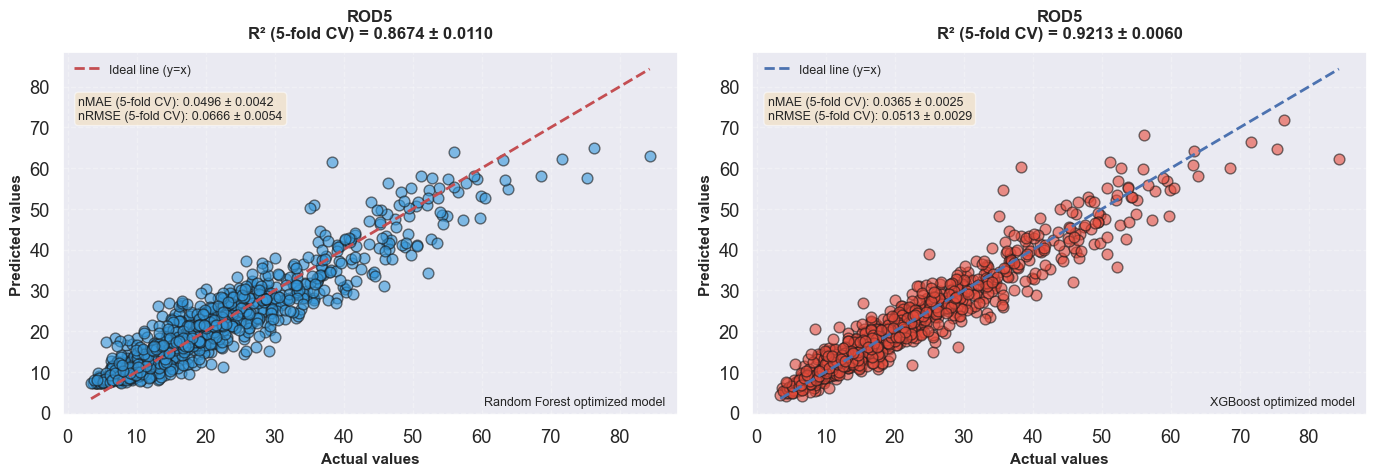

In [14]:
# ============================================================================
# FIGURE 6. nRMSE AND nMAE ERROR DISTRIBUTION (OPTIMIZED MODELS, ROD5)
# ============================================================================

FIGURE_INDICATOR = 'ROD5'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

panels = [
    (rf_imputer, 'Random Forest optimized model', '#3498db', 'r--'),
    (xgb_imputer, 'XGBoost optimized model', '#e74c3c', 'b--'),
]

for ax, (imputer, label, color, line_style) in zip(axes, panels):
    test_data = imputer.get_test_predictions()[FIGURE_INDICATOR]
    cv = imputer.get_cv_scores()[FIGURE_INDICATOR]
    y_true, y_pred = test_data['y_true'], test_data['y_pred']

    ax.scatter(y_true, y_pred, alpha=0.6, edgecolors='k', s=60, color=color)

    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], line_style, lw=2, label='Ideal line (y=x)')

    ax.set_xlabel('Actual values', fontsize=11, fontweight='bold')
    ax.set_ylabel('Predicted values', fontsize=11, fontweight='bold')
    ax.set_title(f"{FIGURE_INDICATOR}\nR² ({CV_FOLDS}-fold CV) = {cv['r2_mean']:.4f} ± {cv['r2_std']:.4f}",
                 fontsize=12, fontweight='bold', pad=10)
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.text(0.025, 0.88,
            f"nMAE ({CV_FOLDS}-fold CV): {cv['nmae_mean']:.4f} ± {cv['nmae_std']:.4f}\n"
            f"nRMSE ({CV_FOLDS}-fold CV): {cv['nrmse_mean']:.4f} ± {cv['nrmse_std']:.4f}",
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    ax.text(0.98, 0.02, label, transform=ax.transAxes, fontsize=9, ha='right', va='bottom')

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'figure_6_rod5_optimized.png'), dpi=300, bbox_inches='tight')
plt.show()

### 6.4 Comparison of baseline and optimized models (Figure 4)

Figure 4 compares the R² values (five-fold CV means) of the baseline (Notebook 1) and the hyperparameter-optimized (this notebook) Random Forest and XGBoost models across the economic indicators.

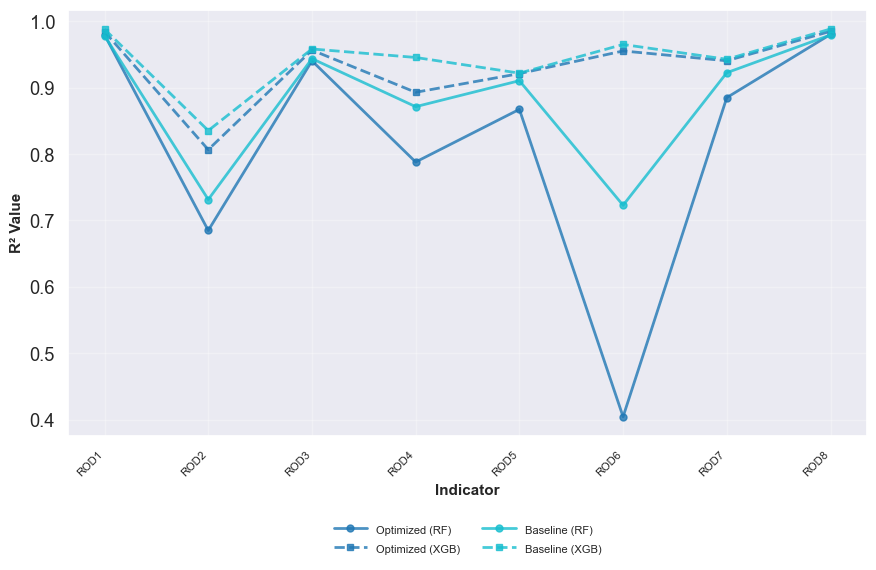

R² values (five-fold CV means):


Random Forest            XGBoost          
                  Baseline Optimized Baseline Optimized
Indicator ID                                           
ROD1                0.9784    0.9798   0.9882    0.9845
ROD2                0.7316    0.6850   0.8354    0.8067
ROD3                0.9438    0.9406   0.9584    0.9566
ROD4                0.8715    0.7881   0.9456    0.8931
ROD5                0.9106    0.8674   0.9220    0.9213
ROD6                0.7229    0.4043   0.9652    0.9554
ROD7                0.9227    0.8851   0.9429    0.9406
ROD8                0.9795    0.9804   0.9885    0.9850

,Baseline,Optimized,Change
Average R²,,,
Random Forest,0.8826,0.8163,-0.0663
XGBoost,0.9433,0.9304,-0.0129


In [15]:
# ============================================================================
# FIGURE 4. COMPARISON OF R² VALUES FOR BASELINE AND OPTIMIZED MODELS
# ============================================================================

BASELINE_METRICS_PATH = os.path.join(RESULTS_DIR, 'cv_metrics_baseline.csv')

if not os.path.exists(BASELINE_METRICS_PATH):
    print(f"File '{BASELINE_METRICS_PATH}' was not found. Run Notebook 1 (baseline models) first.")
else:
    baseline_metrics = pd.read_csv(BASELINE_METRICS_PATH)
    optimized_metrics = pd.concat([
        rf_metrics_df.assign(Model='Random Forest'),
        xgb_metrics_df.assign(Model='XGBoost'),
    ])

    def r2_by_indicator(metrics, model):
        return metrics[metrics['Model'] == model].set_index('Indicator')['R²'].reindex(INDICATOR_IDS)

    experiments = [('Optimized', optimized_metrics), ('Baseline', baseline_metrics)]
    colors = plt.cm.tab10(np.linspace(0, 1, len(experiments)))
    x = np.arange(len(INDICATOR_IDS))

    fig, ax = plt.subplots(figsize=(9, 6))
    for color, (label, metrics) in zip(colors, experiments):
        ax.plot(x, r2_by_indicator(metrics, 'Random Forest'), marker='o', linewidth=2, markersize=5,
                label=f"{label} (RF)", color=color, linestyle='-', alpha=0.8)
        ax.plot(x, r2_by_indicator(metrics, 'XGBoost'), marker='s', linewidth=2, markersize=5,
                label=f"{label} (XGB)", color=color, linestyle='--', alpha=0.8)

    ax.set_xlabel('Indicator', fontsize=11, fontweight='bold')
    ax.set_ylabel('R² Value', fontsize=11, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(INDICATOR_IDS, rotation=45, ha='right', fontsize=8)
    ax.legend(fontsize=8, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.18),
              framealpha=0.9, handlelength=3, handleheight=1.5)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, 'figure_4_r2_baseline_vs_optimized.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # R² values shown in Figure 4
    r2_table = pd.DataFrame({
        ('Random Forest', 'Baseline'): r2_by_indicator(baseline_metrics, 'Random Forest'),
        ('Random Forest', 'Optimized'): r2_by_indicator(optimized_metrics, 'Random Forest'),
        ('XGBoost', 'Baseline'): r2_by_indicator(baseline_metrics, 'XGBoost'),
        ('XGBoost', 'Optimized'): r2_by_indicator(optimized_metrics, 'XGBoost'),
    })
    r2_table.index.name = 'Indicator ID'
    print("R² values (five-fold CV means):")
    display(r2_table.round(4))

    # Overall change after hyperparameter optimization (means across indicators)
    change = pd.DataFrame({
        'Baseline': [r2_table[('Random Forest', 'Baseline')].mean(), r2_table[('XGBoost', 'Baseline')].mean()],
        'Optimized': [r2_table[('Random Forest', 'Optimized')].mean(), r2_table[('XGBoost', 'Optimized')].mean()],
    }, index=['Random Forest', 'XGBoost'])
    change['Change'] = change['Optimized'] - change['Baseline']
    change.index.name = 'Average R²'
    display(change.round(4))

## 7. Imputed datasets

Following the imputation process, a complete dataset of economic indicators is obtained for each model. The imputed datasets are saved to the `results/` directory.

In [16]:
# ============================================================================
# SAVING THE IMPUTED DATASETS
# ============================================================================

for model_name, df_imputed in [('random_forest', df_imputed_rf), ('xgboost', df_imputed_xgb)]:
    path = os.path.join(RESULTS_DIR, f'imputed_dataset_{model_name}_optimized.csv')
    df_imputed.to_csv(path, index=False)
    print(f"{path}: {len(df_imputed):,} rows, "
          f"missing values before = {int(df[INDICATOR_IDS].isna().sum().sum()):,}, "
          f"after = {int(df_imputed[INDICATOR_IDS].isna().sum().sum())}")

results\imputed_dataset_random_forest_optimized.csv: 6,984 rows, missing values before = 17,511, after = 0
results\imputed_dataset_xgboost_optimized.csv: 6,984 rows, missing values before = 17,511, after = 0


## 8. Saving the cross-validation metrics

The per-indicator cross-validation metrics are saved to `results/cv_metrics_optimized.csv.

In [17]:
# ============================================================================
# SAVING THE CROSS-VALIDATION METRICS
# ============================================================================

metric_cols = ['Indicator', 'R²', 'R²_std', 'nRMSE', 'nRMSE_std', 'nMAE', 'nMAE_std', 'sMAPE (%)', 'sMAPE_std', 'Sample size']

cv_metrics = pd.concat([
    rf_metrics_df[metric_cols].assign(Model='Random Forest'),
    xgb_metrics_df[metric_cols].assign(Model='XGBoost'),
])[['Model'] + metric_cols]

metrics_path = os.path.join(RESULTS_DIR, 'cv_metrics_optimized.csv')
cv_metrics.to_csv(metrics_path, index=False)
print(f"Cross-validation metrics saved: {metrics_path}")
display(cv_metrics.round(4))

Cross-validation metrics saved: results\cv_metrics_optimized.csv


,Model,Indicator,R²,R²_std,nRMSE,nRMSE_std,nMAE,nMAE_std,sMAPE (%),sMAPE_std,Sample size
0,Random Forest,ROD1,0.9798,0.0012,0.0275,0.0009,0.0209,0.0005,1.4520,0.0277,4015
1,Random Forest,ROD2,0.6850,0.0651,0.0719,0.0087,0.0438,0.0091,33.9757,1.8345,2583
2,Random Forest,ROD3,0.9406,0.0041,0.0445,0.0026,0.0321,0.0017,11.9479,0.3572,3965
3,Random Forest,ROD4,0.7881,0.0055,0.0856,0.0018,0.0643,0.0009,15.0278,0.4747,3928
4,Random Forest,ROD5,0.8674,0.0110,0.0666,0.0054,0.0496,0.0042,18.4485,0.7405,3532
5,Random Forest,ROD6,0.4043,0.0494,0.0887,0.0038,0.0439,0.0010,95.4852,1.2524,5028
6,Random Forest,ROD7,0.8851,0.0084,0.0512,0.0027,0.0350,0.0024,26.8918,0.9729,3627
7,Random Forest,ROD8,0.9804,0.0026,0.0256,0.0016,0.0187,0.0010,2.3627,0.0491,4015
0,XGBoost,ROD1,0.9845,0.0012,0.0240,0.0008,0.0183,0.0005,1.2713,0.0306,4015
1,XGBoost,ROD2,0.8067,0.0617,0.0555,0.0072,0.0321,0.0064,27.7292,1.1798,2583
